# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [10]:
DATA_PATH = PROJECT_DIR / "data" / "wine.csv"

df = pd.read_csv(DATA_PATH, index_col=0)

In [11]:
print("Forma del DataFrame:")
print(df.shape)
print("\nTipos de datos:")
print(df.dtypes)
print("\nValores nulos:")
print(df.isnull().sum())
print("\nDuplicados:")
print(df.duplicated().sum())
print("\nDistribución del target:")
print(df['target'].value_counts())

Forma del DataFrame:
(178, 13)

Tipos de datos:
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

Valores nulos:
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                     

**Conclusión de calidad:**

> Describe brevemente qué encontraste y qué decisión tomaste.

## 2. Split train/test

In [12]:
df = df.reset_index(drop=True)
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["target"], random_state=RANDOM_STATE
)

In [13]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 13)
Test: (36, 13)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

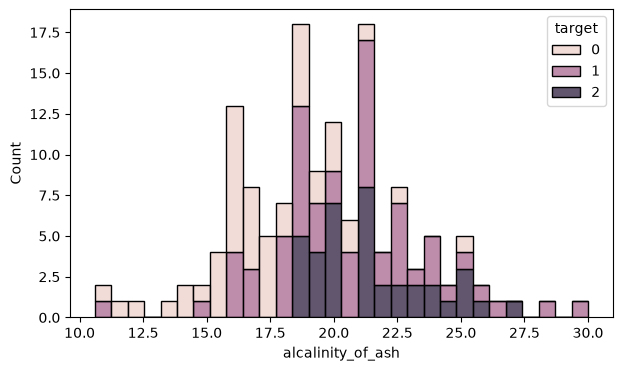

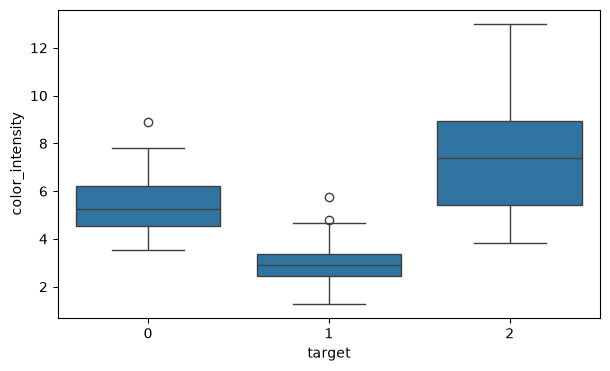

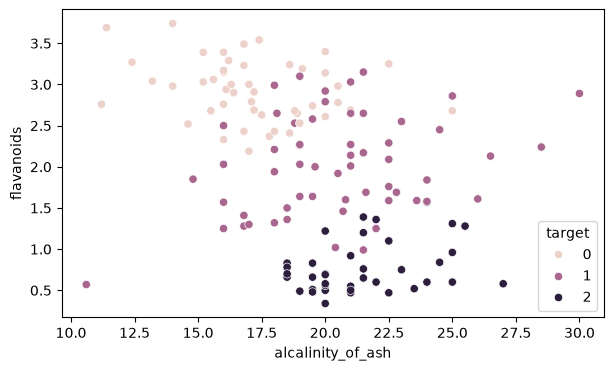

In [17]:
# TODO: crea al menos tres visualizaciones usando solamente train_df

plot1 = sns.histplot(data=train_df, x='alcalinity_of_ash', hue='target', multiple='stack', bins=30)
plt.show()
plot2 = sns.boxplot(data=train_df, x='target', y='color_intensity')
plt.show()
plot3 = sns.scatterplot(data=train_df, x='alcalinity_of_ash', y='flavanoids', hue='target')
plt.show()

**Hallazgos:**

1.
2.
3.

## 4. Persistencia de datos y contrato

In [24]:
# TODO: reinicia los índices y guarda train.csv y test.csv sin el índice
# TODO: crea data_contract.json con target, features, random_state y test_size
train_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)
train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)
data_contract = {
    "target": "target",
    "features": [col for col in df.columns if col != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
}
with open(ARTIFACTS_DIR / "data_contract.json", "w") as f:
    json.dump(data_contract, f, indent=4)

In [25]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [ ] Cargué el CSV desde `data/raw`.
- [ ] Revisé calidad y distribución de la clase.
- [ ] Realicé un split estratificado.
- [ ] No exploré el conjunto de test.
- [ ] Guardé los tres artefactos requeridos.